# Major Health Indicators (Sub-district Level): Visualisation & Analytical Report
*Continuation of the data cleaning and EDA notebook.*

**Dataset:** 500-record sample, 311 raw columns (294 after removing 17 fully empty ones), India sub-district HMIS indicators, 2019–2021.

**Contents**
1. Setup and loading the cleaned data
2. Short column names and data-quality checks
3. Coverage: where and when the data comes from
4. Service delivery: OPD, inpatient, emergencies
5. Maternal health: ANC, deliveries, complications
6. Child health: immunisation cascade, dropout, disease burden
7. Newborn and mortality indicators
8. Family planning
9. State-level comparison heatmap
10. Relationships between indicators
11. Findings report and export

## 1. Setup and loading the cleaned data

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

In [2]:
import os
CLEAN = "Cleaned_Major_Health_Indicators.csv"
RAW   = "Major Health Indicators Sub-district Level_Sample_Data.csv"

if os.path.exists(CLEAN):
    df = pd.read_csv(CLEAN)
    print("Loaded cleaned file:", df.shape)
elif os.path.exists(RAW):
    df = pd.read_csv(RAW)
    df = df.dropna(axis=1, how="all").drop_duplicates().copy()
    print("Cleaned file not found, rebuilt from raw:", df.shape)
else:
    raise FileNotFoundError("Place the cleaned or raw CSV in the same folder as this notebook.")

Cleaned file not found, rebuilt from raw: (500, 294)


## 2. Short column names and data-quality checks
The cleaned names are long (`label_(code)`). The code in the final brackets is a compact, unique identifier, so it is used from here on. This also removes the need to guess names such as `allopathic_opd_attendance`, which did not match any column in the earlier indicator step (only one of the four selected indicators was found).

In [3]:
def short(c):
    m = re.search(r"\(([A-Za-z0-9_]+)\)\s*$", str(c).strip())
    return m.group(1).lower() if m else str(c).strip().lower()

lookup = {short(c): c for c in df.columns}          # short -> long label
df.columns = [short(c) for c in df.columns]
assert df.columns.is_unique, "Duplicate short names found"

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

id_cols = ["date","year","month","state_name","state_code","district_name","district_code",
           "subdistrict_name","subdistrict_code","sector"]
num_cols = [c for c in df.columns if c not in id_cols and pd.api.types.is_numeric_dtype(df[c])]
print(f"{len(num_cols)} numeric indicators, {len(df)} records")
df[id_cols].head()

286 numeric indicators, 500 records


,date,year,month,state_name,state_code,district_name,district_code,subdistrict_name,subdistrict_code,sector
0,2021-04-01,2021,2021-04-01,Bihar,10,Supaul,223,Basantpur,1102,Public
1,2019-12-01,2019,2019-12-01,Madhya Pradesh,23,Sehore,427,Nasrullaganj,3587,Private
2,2019-08-01,2019,2019-08-01,Bihar,10,Purnia,214,Dagarua,1141,Rural
3,2019-03-01,2019,2019-03-01,Telangana,36,Adilabad,501,Adilabad,4306,Rural
4,2021-05-01,2021,2021-05-01,Madhya Pradesh,23,Umaria,436,Others,9999,Total


In [4]:
# Data-quality snapshot
zero_share = (df[num_cols] == 0).mean().mean()
all_zero_rows = (df[num_cols].sum(axis=1) == 0)
always_zero = [c for c in num_cols if df[c].sum() == 0]
neg_vals = (df[num_cols] < 0).sum().sum()

quality = pd.DataFrame({
    "Check": ["Records", "Numeric indicators", "Share of cells equal to 0",
              "Records where every indicator is 0", "Indicators that are 0 in every record",
              "Negative values", "Rows with 'Total' sector", "Rows with sub-district 'Others' (code 9999)"],
    "Result": [len(df), len(num_cols), f"{zero_share:.1%}", int(all_zero_rows.sum()),
               len(always_zero), int(neg_vals), int((df.sector=="Total").sum()),
               int((df.subdistrict_code==9999).sum())]
})
quality

,Check,Result
0,Records,500
1,Numeric indicators,286
2,Share of cells equal to 0,71.0%
3,Records where every indicator is 0,135
4,Indicators that are 0 in every record,10
5,Negative values,0
6,Rows with 'Total' sector,88
7,Rows with sub-district 'Others' (code 9999),74


**Reading this table.** Health facility data reports zero for services not provided and for months not reported, so a very high zero share is expected and should not be treated as "clean" data. Two further structural points matter for every chart below:

- `sector` mixes **Public, Private, Rural, Urban and Total**. Total is an aggregate of the others, so summing across sectors would double count. Sector comparisons below exclude *Total*, and state comparisons use **averages per record** rather than raw sums.
- Sub-district `Others` (code 9999) is also an aggregate bucket.

## 3. Coverage: where and when the data comes from

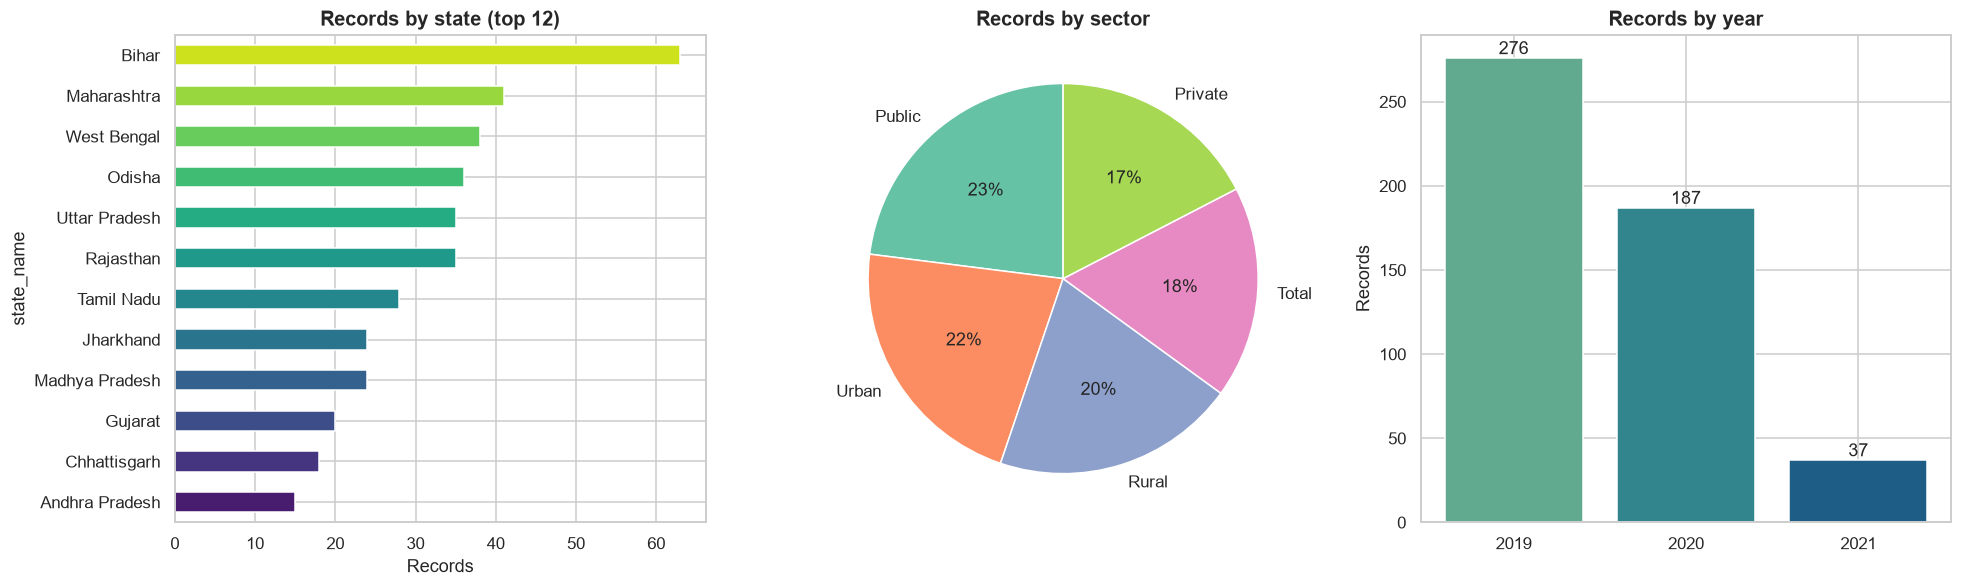

Date range: 2019-01-01 to 2021-05-01 | distinct dates: 25


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

top_states = df.state_name.value_counts().head(12).sort_values()
top_states.plot.barh(ax=ax[0], color=sns.color_palette("viridis", 12))
ax[0].set_title("Records by state (top 12)"); ax[0].set_xlabel("Records")

sec = df.sector.value_counts()
ax[1].pie(sec, labels=sec.index, autopct="%1.0f%%", startangle=90,
          colors=sns.color_palette("Set2", len(sec)), wedgeprops={"edgecolor":"white"})
ax[1].set_title("Records by sector")

yr = df.year.value_counts().sort_index()
bars = ax[2].bar(yr.index.astype(str), yr.values, color=sns.color_palette("crest", len(yr)))
ax[2].bar_label(bars); ax[2].set_title("Records by year"); ax[2].set_ylabel("Records")
plt.tight_layout(); plt.show()
print("Date range:", df.date.min().date(), "to", df.date.max().date(), "| distinct dates:", df.date.nunique())

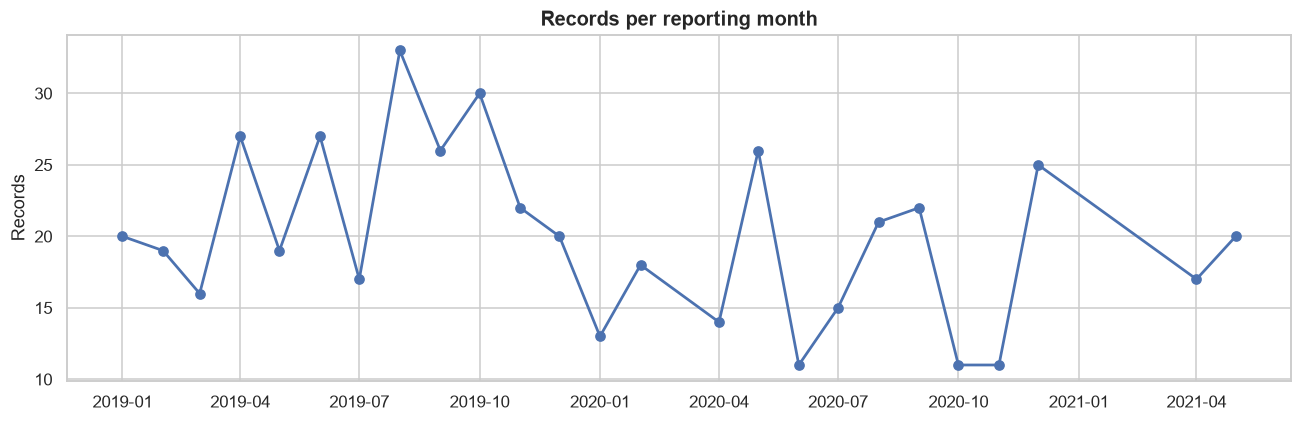

In [6]:
m = df.groupby("month").size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m.index, m.values, marker="o", lw=1.8)
ax.set_title("Records per reporting month"); ax.set_ylabel("Records"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Note on dates.** Dates in this extract are the first of a reporting period and most fall in 2019–2020, with a thin 2021 tail. Year-on-year changes in this sample therefore reflect **which sub-districts happened to be sampled** as much as real change. Treat time trends as indicative only.

## 4. Service delivery: OPD, inpatient and emergency load

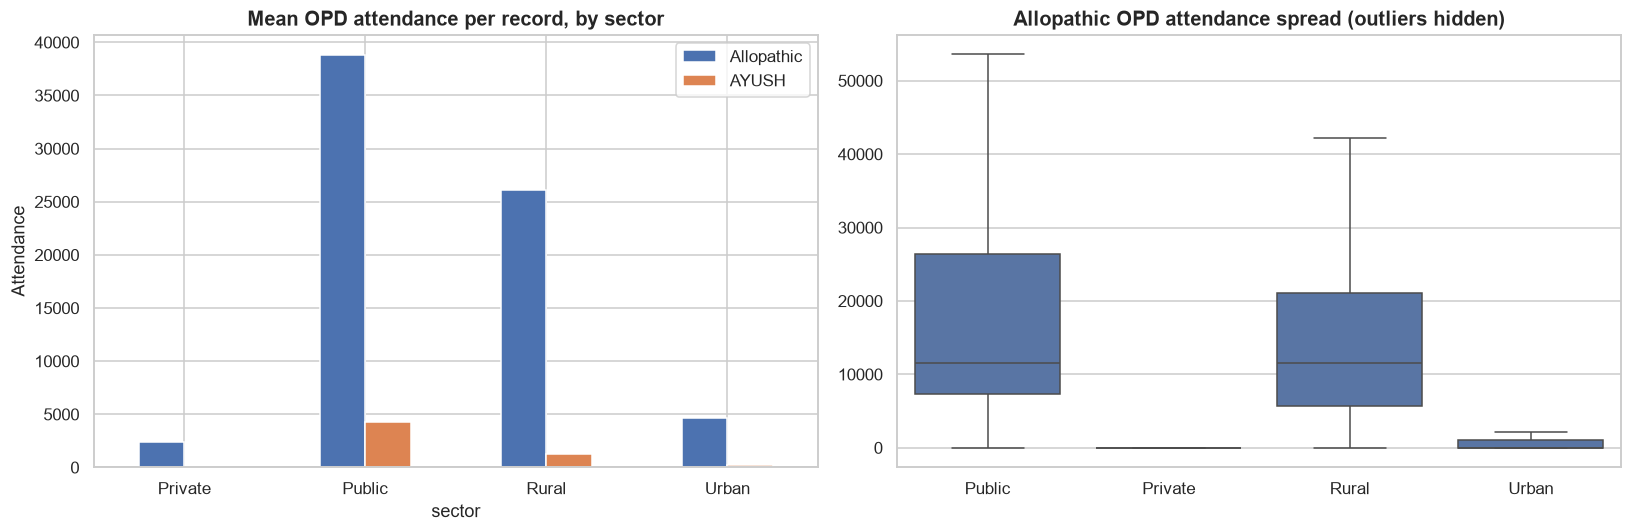

In [7]:
sec_df = df[df.sector != "Total"]
opd = ["allopathic_outpatient_attendance", "ayush_outpatient_attendance"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sec_means = sec_df.groupby("sector")[opd].mean().rename(columns={
    "allopathic_outpatient_attendance":"Allopathic", "ayush_outpatient_attendance":"AYUSH"})
sec_means.plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Mean OPD attendance per record, by sector"); ax[0].set_ylabel("Attendance")

sns.boxplot(data=sec_df, x="sector", y="allopathic_outpatient_attendance", ax=ax[1], showfliers=False)
ax[1].set_title("Allopathic OPD attendance spread (outliers hidden)"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

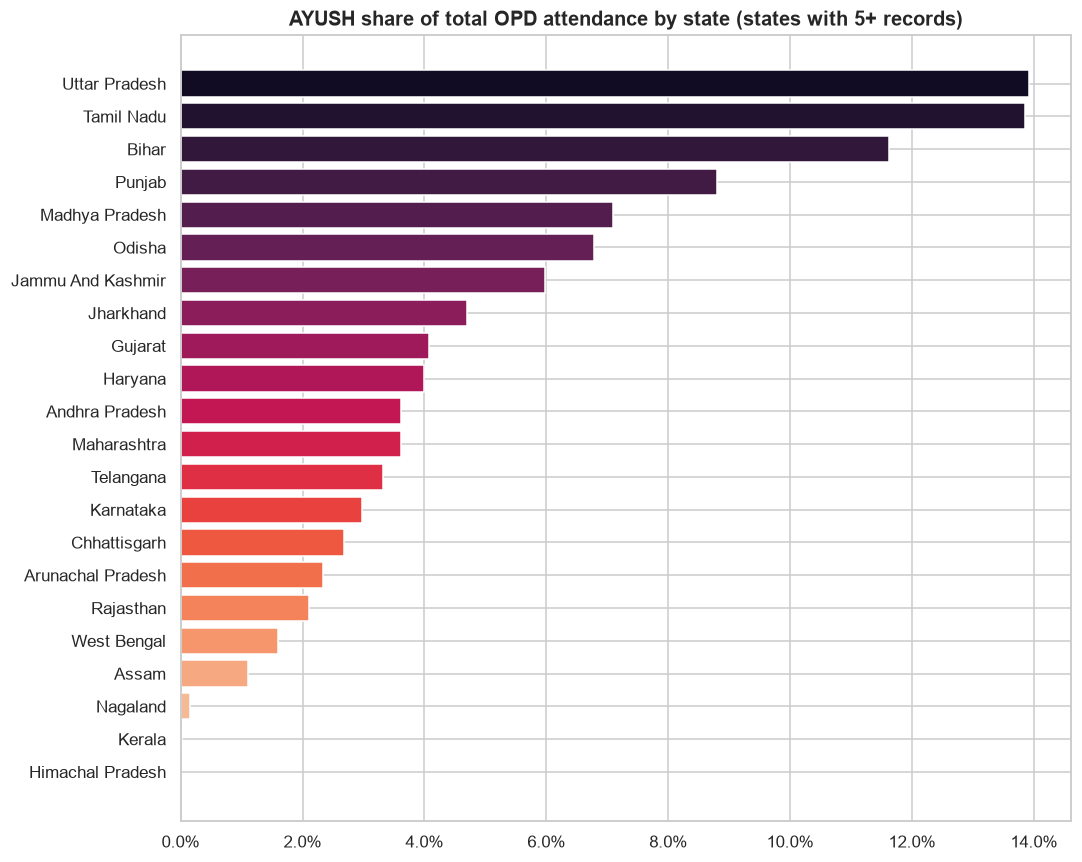

In [8]:
state_opd = (df.groupby("state_name")[opd].mean()
               .assign(ayush_share=lambda d: d.ayush_outpatient_attendance /
                       (d.allopathic_outpatient_attendance + d.ayush_outpatient_attendance))
               .dropna())
counts = df.state_name.value_counts()
state_opd = state_opd[counts.reindex(state_opd.index) >= 5].sort_values("ayush_share")

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(state_opd.index, state_opd.ayush_share, color=sns.color_palette("rocket_r", len(state_opd)))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("AYUSH share of total OPD attendance by state (states with 5+ records)")
plt.tight_layout(); plt.show()

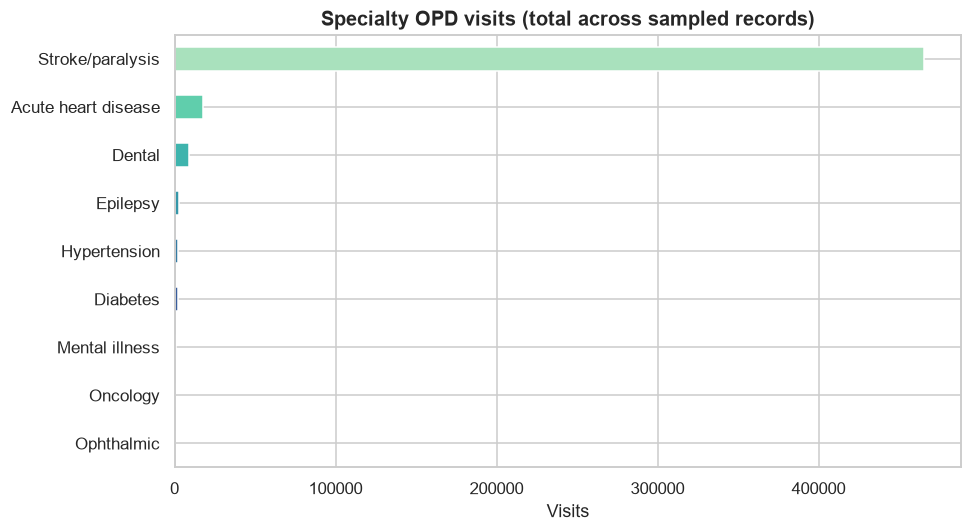

In [9]:
ncd = {"outpatient_hypertension":"Hypertension","outpatient_diabetes":"Diabetes",
       "outpatient_dental":"Dental","outpatient_mental_illness":"Mental illness",
       "outpatient_oncology":"Oncology","outpatient_epilepsy":"Epilepsy",
       "outpatient_stroke_paralysis":"Stroke/paralysis","outpatient_acute_heart_diseases":"Acute heart disease",
       "outpatient_ophthalmic_related":"Ophthalmic"}
t = df[list(ncd)].sum().rename(index=ncd).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
t.plot.barh(ax=ax, color=sns.color_palette("mako", len(t)))
ax.set_title("Specialty OPD visits (total across sampled records)"); ax.set_xlabel("Visits")
plt.tight_layout(); plt.show()

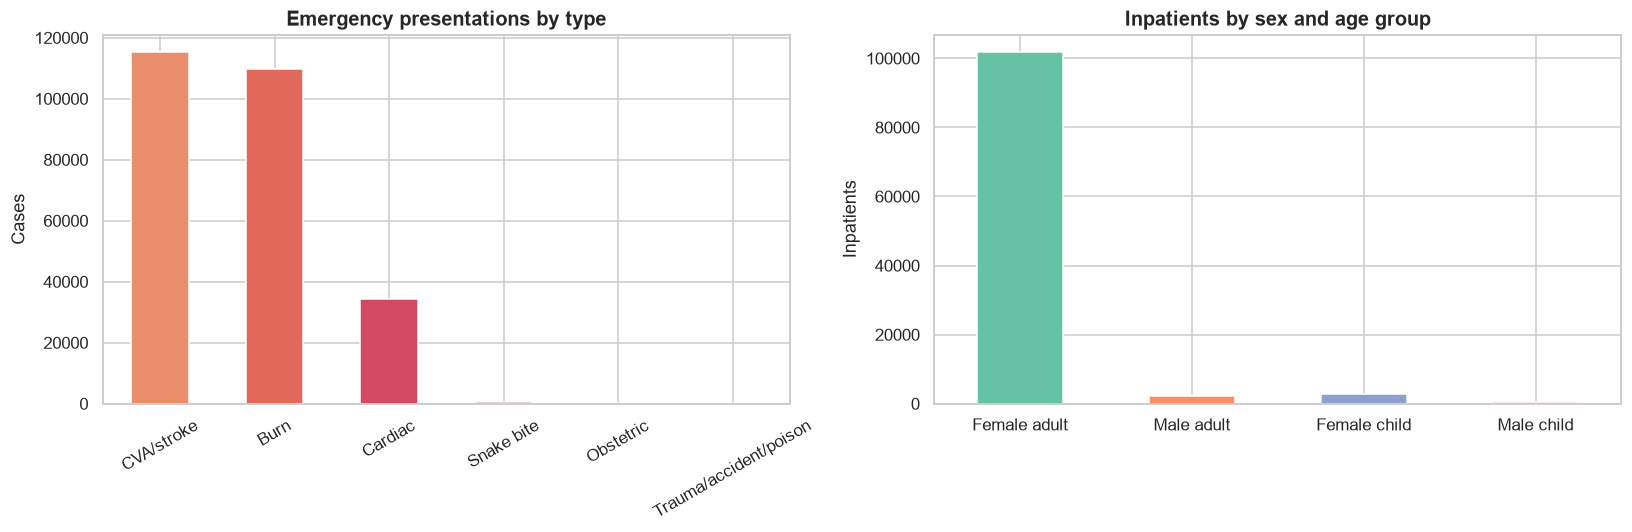

In [10]:
emer = {"emer_cardiac":"Cardiac","emer_burn":"Burn","emer_cva":"CVA/stroke","emer_ob_comp":"Obstetric",
        "emer_snakebite":"Snake bite","emer_trauma_acc_poison":"Trauma/accident/poison"}
e = df[list(emer)].sum().rename(index=emer).sort_values(ascending=False)
inp = df[["inpatient_female_adults","inpatient_male_adults",
          "inpatient_female_children18yrs","inpatient_male_children18yrs"]].sum()
inp.index = ["Female adult","Male adult","Female child","Male child"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
e.plot.bar(ax=ax[0], color=sns.color_palette("flare", len(e)), rot=30)
ax[0].set_title("Emergency presentations by type"); ax[0].set_ylabel("Cases")
inp.plot.bar(ax=ax[1], color=sns.color_palette("Set2", 4), rot=0)
ax[1].set_title("Inpatients by sex and age group"); ax[1].set_ylabel("Inpatients")
plt.tight_layout(); plt.show()

## 5. Maternal health

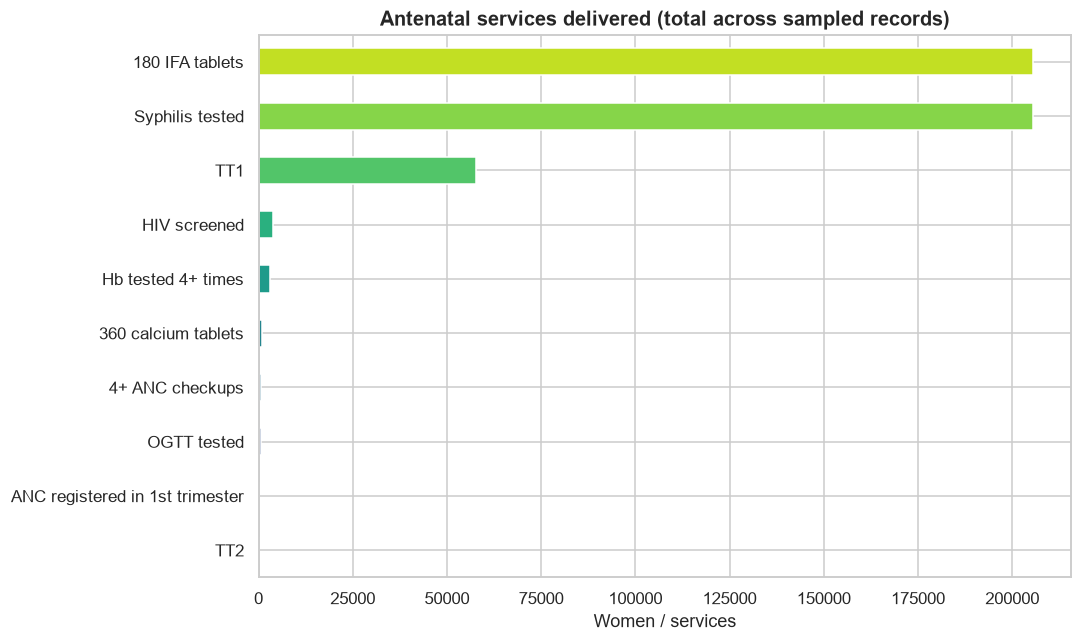

In [11]:
def safe_ratio(num, den):
    return np.where(den > 0, num / den.where(den > 0), np.nan)

# ANC / supplementation cascade, expressed relative to ANC-registered-in-first-trimester is not valid
# (different denominators), so each indicator is shown as a total count in a funnel-style bar.
anc = {"anc_1trim_12w":"ANC registered in 1st trimester","pw_tt1":"TT1","pw_tt2":"TT2",
       "pw_4plus_anc":"4+ ANC checkups","pw_ifa180":"180 IFA tablets","pw_cal360":"360 calcium tablets",
       "pw_hb4plus_test":"Hb tested 4+ times","pw_ogtt_test":"OGTT tested","pw_hiv_screen":"HIV screened",
       "pw_syph_test":"Syphilis tested"}
a = df[list(anc)].sum().rename(index=anc).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
a.plot.barh(ax=ax, color=sns.color_palette("viridis", len(a)))
ax.set_title("Antenatal services delivered (total across sampled records)"); ax.set_xlabel("Women / services")
plt.tight_layout(); plt.show()

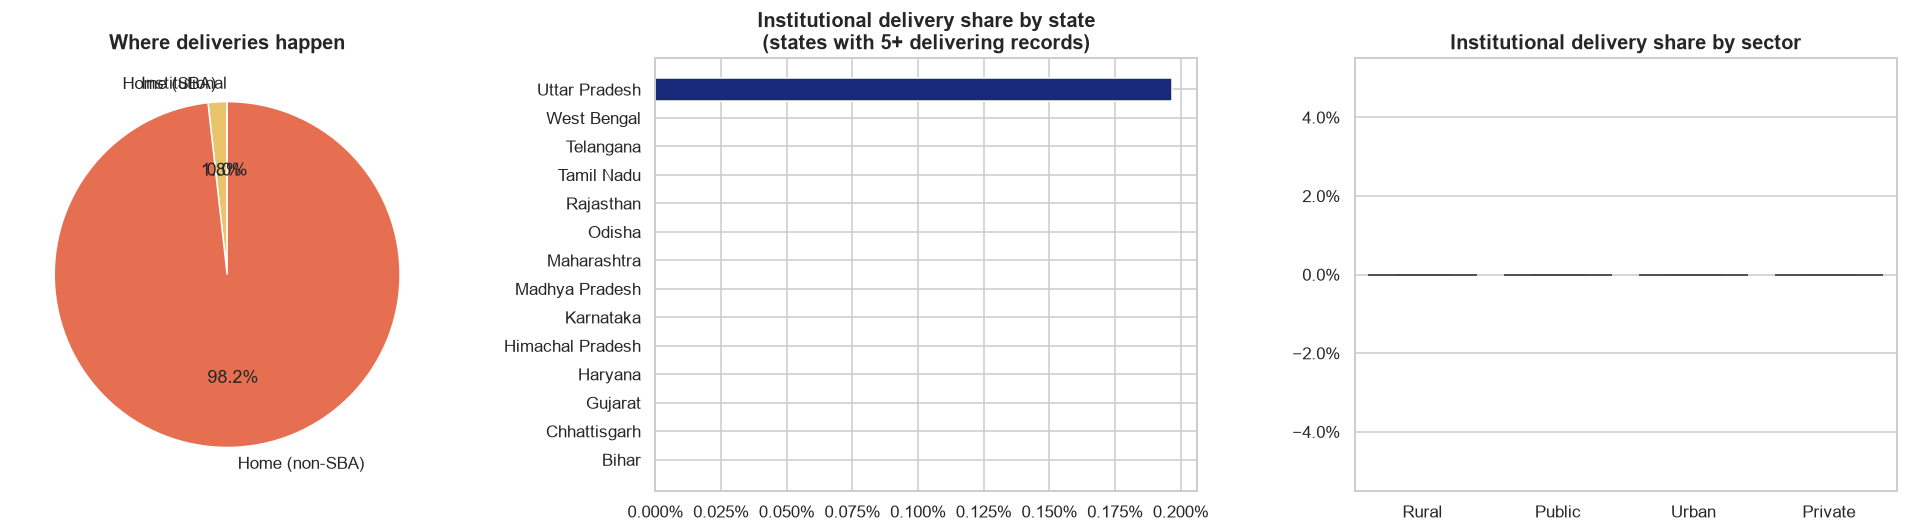

In [12]:
d = df.copy()
d["inst"] = d.inst_deliv_csec
d["home"] = d.home_deliv_sba + d.home_deliv_non_sba
d["deliveries"] = d.inst + d.home
d["inst_share"] = safe_ratio(d.inst, d.deliveries)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

tot = d[["inst","home_deliv_sba","home_deliv_non_sba"]].sum()
tot.index = ["Institutional","Home (SBA)","Home (non-SBA)"]
ax[0].pie(tot, labels=tot.index, autopct="%1.1f%%", startangle=90,
          colors=["#2a9d8f","#e9c46a","#e76f51"], wedgeprops={"edgecolor":"white"})
ax[0].set_title("Where deliveries happen")

s = (d[d.deliveries > 0].groupby("state_name")
       .apply(lambda g: g.inst.sum() / g.deliveries.sum())
       .rename("share"))
n = d[d.deliveries > 0].groupby("state_name").size()
s = s[n >= 5].sort_values()
ax[1].barh(s.index, s.values, color=sns.color_palette("YlGnBu", len(s)))
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_title("Institutional delivery share by state\n(states with 5+ delivering records)")

sd = d[(d.sector != "Total") & (d.deliveries > 0)]
sns.boxplot(data=sd, x="sector", y="inst_share", ax=ax[2], showfliers=False)
ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[2].set_title("Institutional delivery share by sector"); ax[2].set_xlabel(""); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

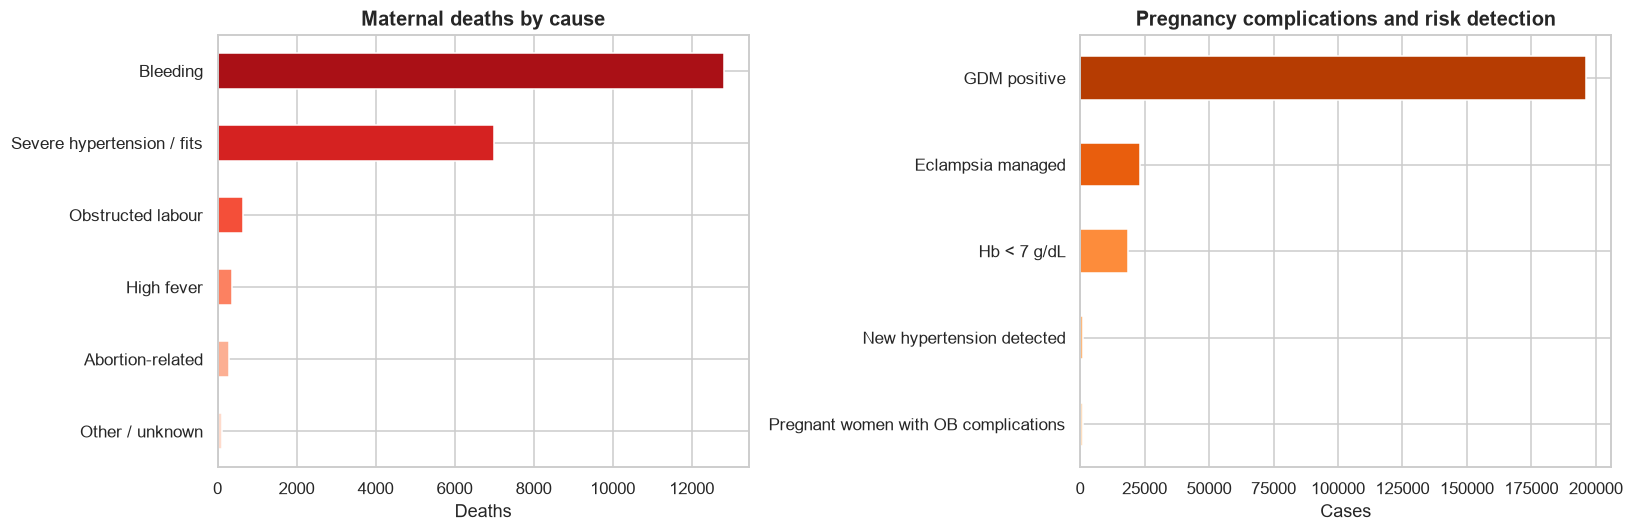

Total maternal deaths in sample: 21215


In [13]:
mat = {"mat_death_bleed":"Bleeding","mat_death_htn_fits":"Severe hypertension / fits","mat_death_fever":"High fever",
       "mat_death_ob_lab":"Obstructed labour","mat_death_abort":"Abortion-related","mat_death_unknown":"Other / unknown"}
comp = {"preg_ob_comp":"Pregnant women with OB complications","eclampsia_deliv_mgd":"Eclampsia managed",
        "pw_gdm_pos":"GDM positive","new_htn_detect_pw":"New hypertension detected",
        "pw_hb_lt7":"Hb < 7 g/dL"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
md_ = df[list(mat)].sum().rename(index=mat).sort_values()
md_.plot.barh(ax=ax[0], color=sns.color_palette("Reds", len(md_)))
ax[0].set_title("Maternal deaths by cause"); ax[0].set_xlabel("Deaths")
cp = df[list(comp)].sum().rename(index=comp).sort_values()
cp.plot.barh(ax=ax[1], color=sns.color_palette("Oranges", len(cp)))
ax[1].set_title("Pregnancy complications and risk detection"); ax[1].set_xlabel("Cases")
plt.tight_layout(); plt.show()

print("Total maternal deaths in sample:", int(df[list(mat)].sum().sum()))

## 6. Child health

### 6.1 Immunisation cascade

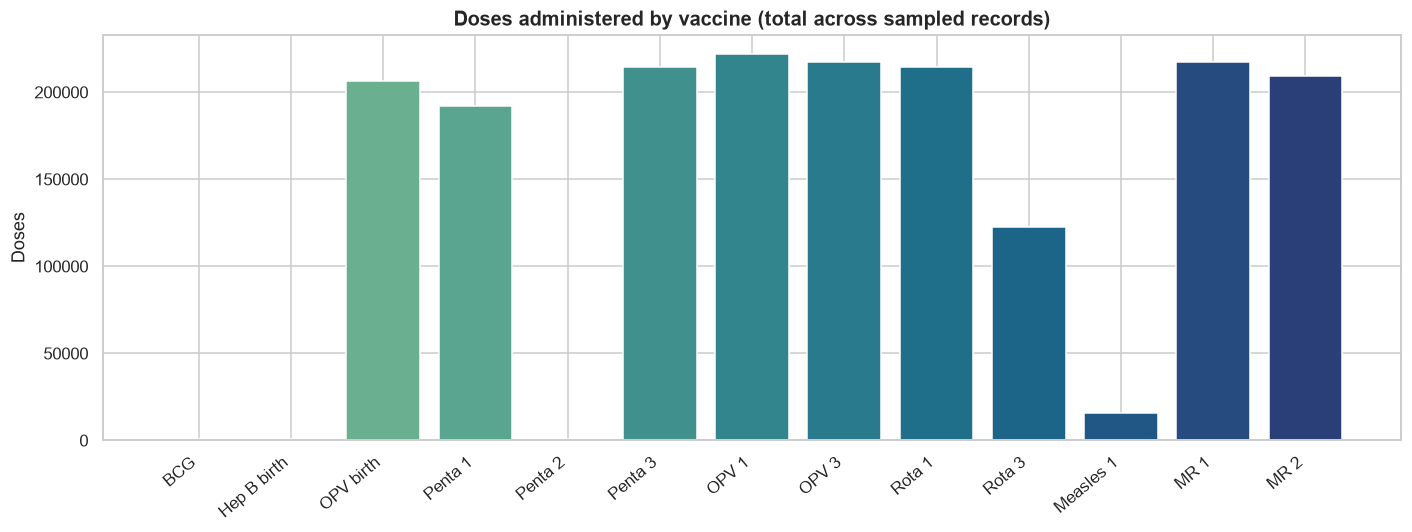

In [14]:
vac = {"child_bcg":"BCG","child_hepb0":"Hep B birth","child_opv0":"OPV birth",
       "child_penta1":"Penta 1","child_penta2":"Penta 2","child_penta3":"Penta 3",
       "child_opv1":"OPV 1","child_opv3":"OPV 3","child_rota1":"Rota 1","child_rota3":"Rota 3",
       "child_meas1":"Measles 1","child_mr1":"MR 1","child_16_24m_mmr2":"MR 2"}
v = df[list(vac)].sum().rename(index=vac)

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(v.index, v.values, color=sns.color_palette("crest", len(v)))
ax.set_title("Doses administered by vaccine (total across sampled records)")
ax.set_ylabel("Doses"); plt.xticks(rotation=40, ha="right")
plt.tight_layout(); plt.show()

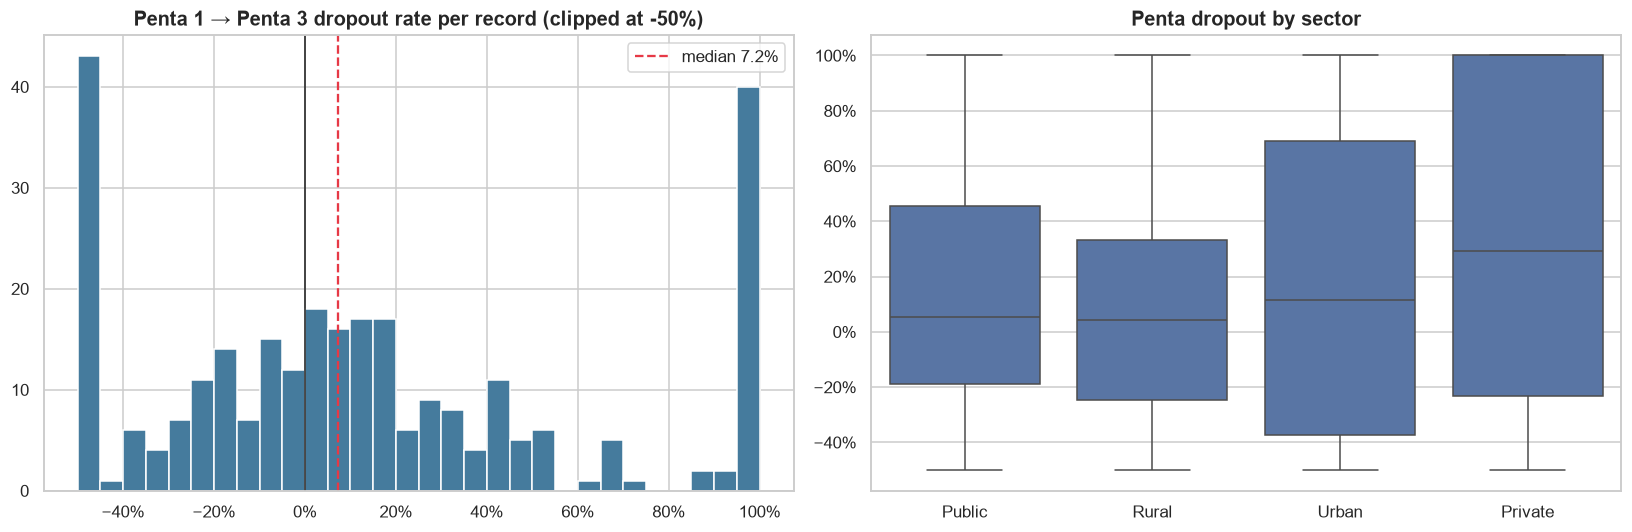

Records with Penta 1 > 0: 288  |  with negative dropout (Penta 3 > Penta 1): 41.7%


In [15]:
pr = df[(df.child_penta1 > 0)].copy()
pr["penta_dropout"] = (pr.child_penta1 - pr.child_penta3) / pr.child_penta1
pr["meas_dropout_vs_penta1"] = (pr.child_penta1 - pr.child_meas1) / pr.child_penta1
# Dropout can be negative when later doses exceed earlier ones (reporting/catchment mismatch)
neg_share = (pr.penta_dropout < 0).mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].hist(pr.penta_dropout.clip(-0.5, 1), bins=30, color="#457b9d", edgecolor="white")
ax[0].axvline(0, color="k", lw=1)
ax[0].axvline(pr.penta_dropout.median(), color="#e63946", ls="--", label=f"median {pr.penta_dropout.median():.1%}")
ax[0].set_title("Penta 1 → Penta 3 dropout rate per record (clipped at -50%)")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].legend()

sdr = pr[pr.sector != "Total"]
sns.boxplot(data=sdr, x="sector", y=sdr.penta_dropout.clip(-0.5, 1), ax=ax[1], showfliers=False)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_title("Penta dropout by sector"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Records with Penta 1 > 0: {len(pr)}  |  with negative dropout (Penta 3 > Penta 1): {neg_share:.1%}")

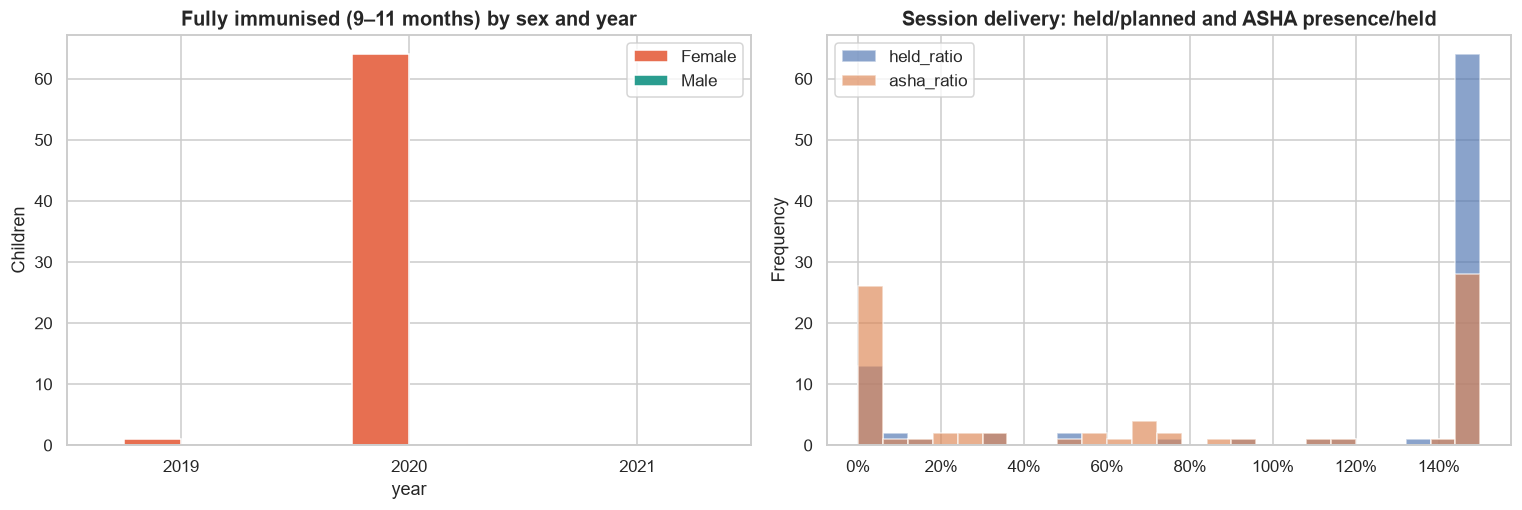

Median sessions held vs planned: 502%


In [16]:
fi = df.assign(full_imm=df.child_9_11m_full_imm_f + df.child_9_11m_full_imm_m,
               fi_f=df.child_9_11m_full_imm_f, fi_m=df.child_9_11m_full_imm_m)
g = fi.groupby("year")[["fi_f","fi_m"]].sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
g.rename(columns={"fi_f":"Female","fi_m":"Male"}).plot.bar(ax=ax[0], rot=0, color=["#e76f51","#2a9d8f"])
ax[0].set_title("Fully immunised (9–11 months) by sex and year"); ax[0].set_ylabel("Children")

sess = df[df.imm_sess_plan > 0].copy()
sess["held_ratio"] = sess.imm_sess_held / sess.imm_sess_plan
sess["asha_ratio"] = sess.imm_sess_asha / sess.imm_sess_held.where(sess.imm_sess_held > 0)
sess[["held_ratio","asha_ratio"]].clip(0, 1.5).plot.hist(bins=25, alpha=.65, ax=ax[1], edgecolor="white")
ax[1].set_title("Session delivery: held/planned and ASHA presence/held")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()
print("Median sessions held vs planned:", f"{sess.held_ratio.median():.0%}")

### 6.2 Childhood disease burden and child deaths

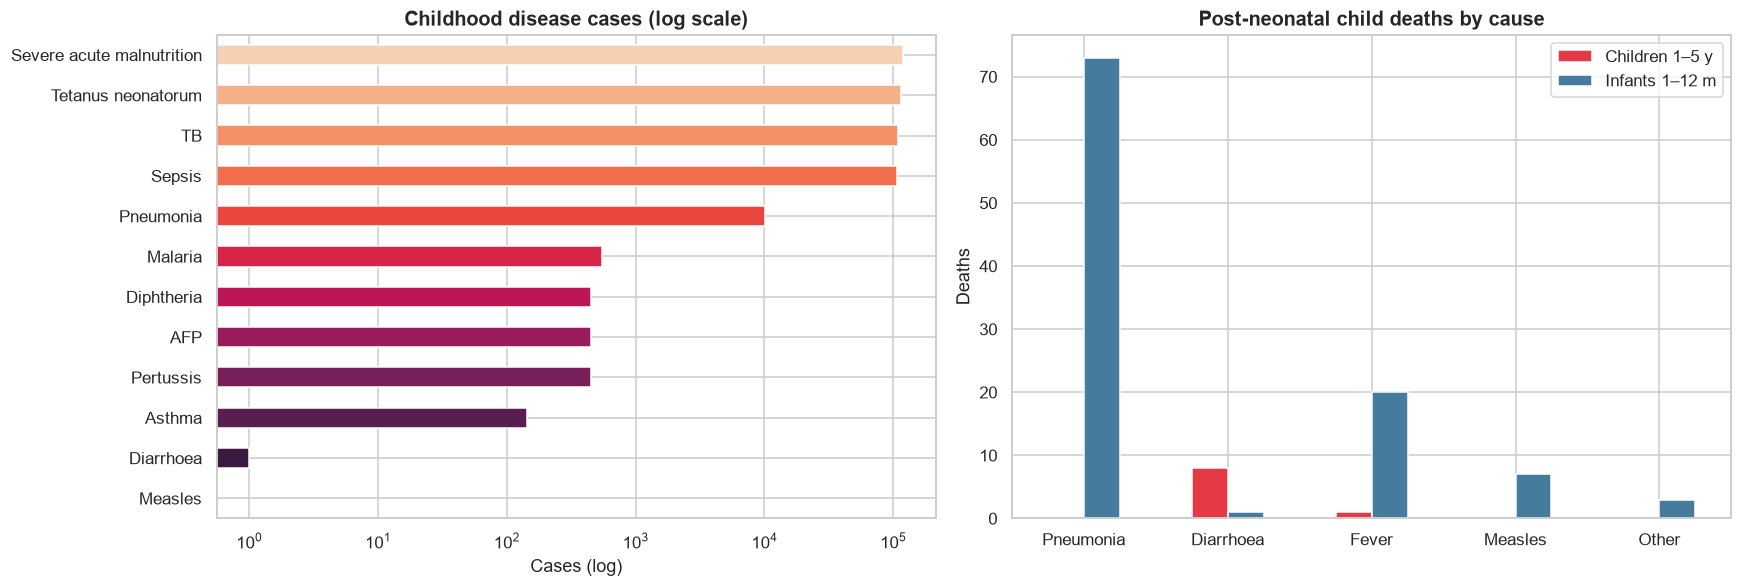

In [17]:
dis = {"child_diarr":"Diarrhoea","child_pneumonia":"Pneumonia","child_asthma":"Asthma",
       "child_sam":"Severe acute malnutrition","child_sepsis":"Sepsis","child_malaria":"Malaria",
       "child_tb":"TB","child_measles":"Measles","child_pertussis":"Pertussis",
       "child_afp":"AFP","child_diphtheria":"Diphtheria","child_tet_neon":"Tetanus neonatorum"}
dd = df[list(dis)].sum().rename(index=dis).sort_values()
cd = {"child_death_1_5y_pneum":"Pneumonia","child_death_1_5y_diarr":"Diarrhoea",
      "child_death_1_5y_fever":"Fever","child_death_1_5y_measles":"Measles","child_death_1_5y_other":"Other"}
idt = {"inf_death_1_12m_pneum":"Pneumonia","inf_death_1_12m_diarr":"Diarrhoea",
       "inf_death_1_12m_fever":"Fever","inf_death_1_12m_measles":"Measles","inf_death_1_12m_other":"Other"}
dm = pd.DataFrame({"Children 1–5 y": df[list(cd)].sum().rename(index=cd),
                   "Infants 1–12 m": df[list(idt)].sum().rename(index=idt)})

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
dd.plot.barh(ax=ax[0], color=sns.color_palette("rocket", len(dd)))
ax[0].set_title("Childhood disease cases (log scale)"); ax[0].set_xscale("log"); ax[0].set_xlabel("Cases (log)")
dm.plot.bar(ax=ax[1], rot=0, color=["#e63946","#457b9d"])
ax[1].set_title("Post-neonatal child deaths by cause"); ax[1].set_ylabel("Deaths")
plt.tight_layout(); plt.show()

## 7. Newborn and mortality indicators

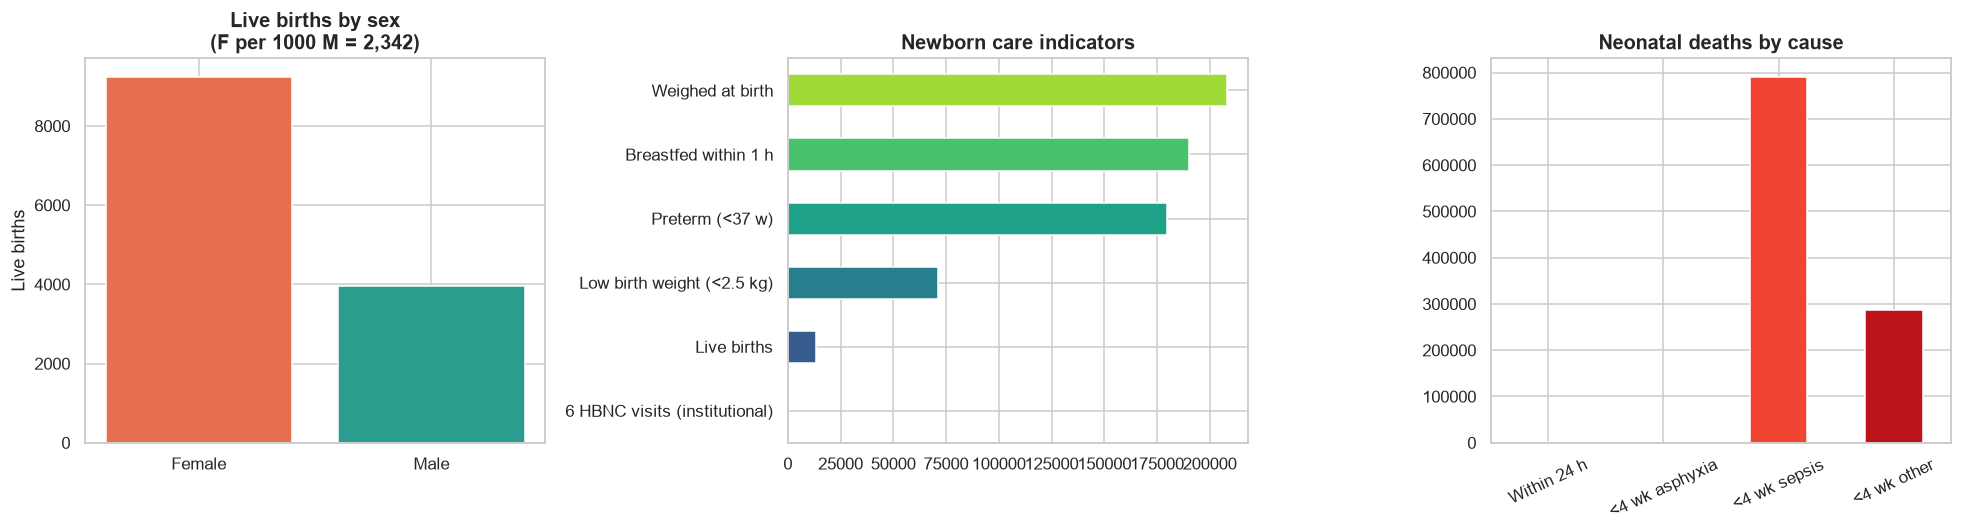

Low birth weight among weighed newborns: 34.3%


In [18]:
lb = df[["live_birth_female","live_birth_male"]].sum()
sex_ratio = lb["live_birth_female"] / lb["live_birth_male"] * 1000 if lb["live_birth_male"] else np.nan

nb_cols = {"nb_weighed_birth":"Weighed at birth","nb_bf_1hr":"Breastfed within 1 h",
           "nb_lt2_5kg":"Low birth weight (<2.5 kg)","preterm_nb":"Preterm (<37 w)",
           "nb_hbnc6_inst":"6 HBNC visits (institutional)"}
nbv = df[list(nb_cols)].sum().rename(index=nb_cols)
nbv["Live births"] = lb.sum()
nbv = nbv.sort_values()

inf = {"inf_death_24h":"Within 24 h","inf_death_4w_asphyx":"<4 wk asphyxia",
       "inf_death_4w_sepsis":"<4 wk sepsis","inf_death_4w_other":"<4 wk other"}
inv = df[list(inf)].sum().rename(index=inf)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].bar(["Female","Male"], lb.values, color=["#e76f51","#2a9d8f"])
ax[0].set_title(f"Live births by sex\n(F per 1000 M = {sex_ratio:,.0f})"); ax[0].set_ylabel("Live births")
nbv.plot.barh(ax=ax[1], color=sns.color_palette("viridis", len(nbv)))
ax[1].set_title("Newborn care indicators")
inv.plot.bar(ax=ax[2], rot=25, color=sns.color_palette("Reds", 4))
ax[2].set_title("Neonatal deaths by cause")
plt.tight_layout(); plt.show()

lbw_rate = df.nb_lt2_5kg.sum() / df.nb_weighed_birth.sum() if df.nb_weighed_birth.sum() else np.nan
print(f"Low birth weight among weighed newborns: {lbw_rate:.1%}")

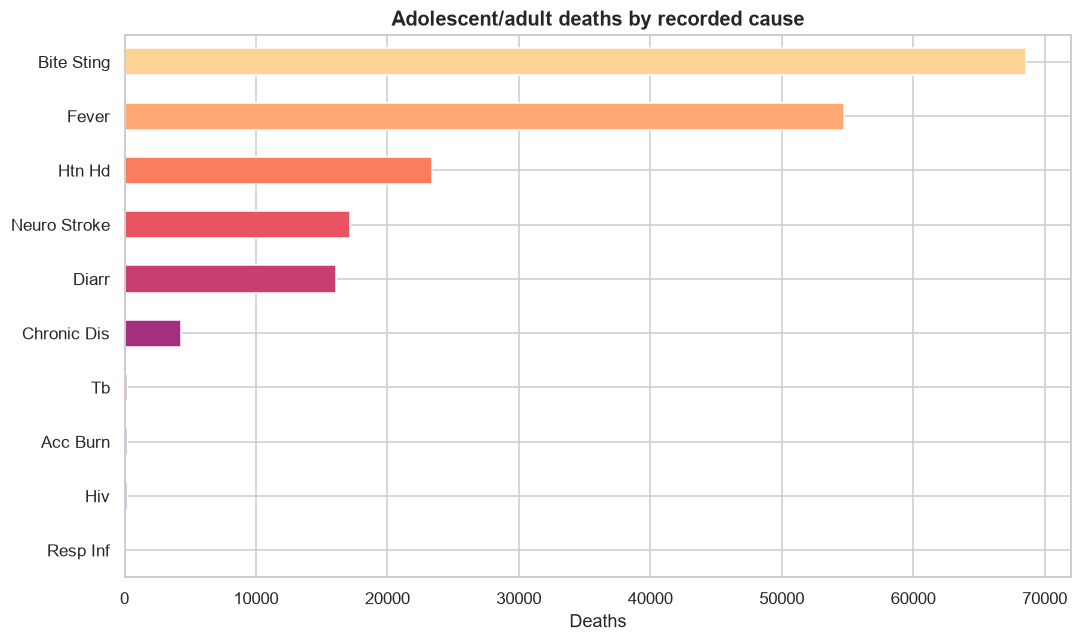

In [19]:
ad = {c:c.replace("adol_death_","").replace("_"," ").title() for c in df.columns if c.startswith("adol_death_")}
adv = df[list(ad)].sum().rename(index=ad).sort_values()
adv = adv[adv > 0]
fig, ax = plt.subplots(figsize=(10, 6))
adv.plot.barh(ax=ax, color=sns.color_palette("magma", len(adv)))
ax.set_title("Adolescent/adult deaths by recorded cause"); ax.set_xlabel("Deaths")
plt.tight_layout(); plt.show()

## 8. Family planning

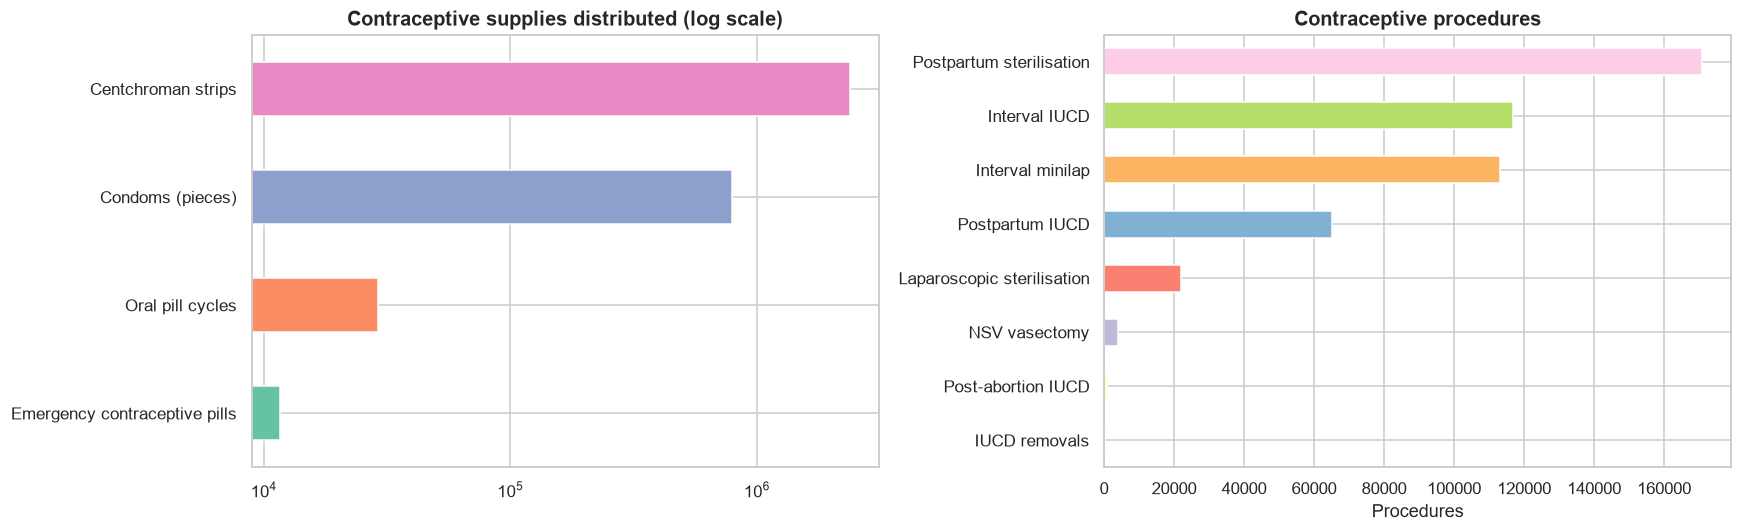

Male (NSV) share of all sterilisation procedures: 1.3%


In [20]:
fp = {"condom_pcs_dist":"Condoms (pieces)","cop_cycles_dist":"Oral pill cycles",
      "centchroman_strips":"Centchroman strips","ecp_given":"Emergency contraceptive pills"}
proc = {"int_iucd_ins":"Interval IUCD","ppiucd_48h":"Postpartum IUCD","pa_iucd_12d":"Post-abortion IUCD",
        "pp_ster_7d":"Postpartum sterilisation","lap_ster_excl_pa":"Laparoscopic sterilisation",
        "int_minilap":"Interval minilap","nsv_done":"NSV vasectomy","iucd_removals":"IUCD removals"}
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
f1 = df[list(fp)].sum().rename(index=fp).sort_values()
f1.plot.barh(ax=ax[0], color=sns.color_palette("Set2", len(f1)))
ax[0].set_xscale("log"); ax[0].set_title("Contraceptive supplies distributed (log scale)")
f2 = df[list(proc)].sum().rename(index=proc).sort_values()
f2.plot.barh(ax=ax[1], color=sns.color_palette("Set3", len(f2)))
ax[1].set_title("Contraceptive procedures"); ax[1].set_xlabel("Procedures")
plt.tight_layout(); plt.show()

male_share = df.nsv_done.sum() / (df.nsv_done.sum() + df.lap_ster_excl_pa.sum() + df.int_minilap.sum() + df.pp_ster_7d.sum())
print(f"Male (NSV) share of all sterilisation procedures: {male_share:.1%}")

## 9. State-level comparison

To compare states fairly with an uneven sample, each indicator is converted to a **per-record mean** and then standardised (z-score across states). Only states with at least 8 records are shown. Treat this as a screening view, not a ranking.

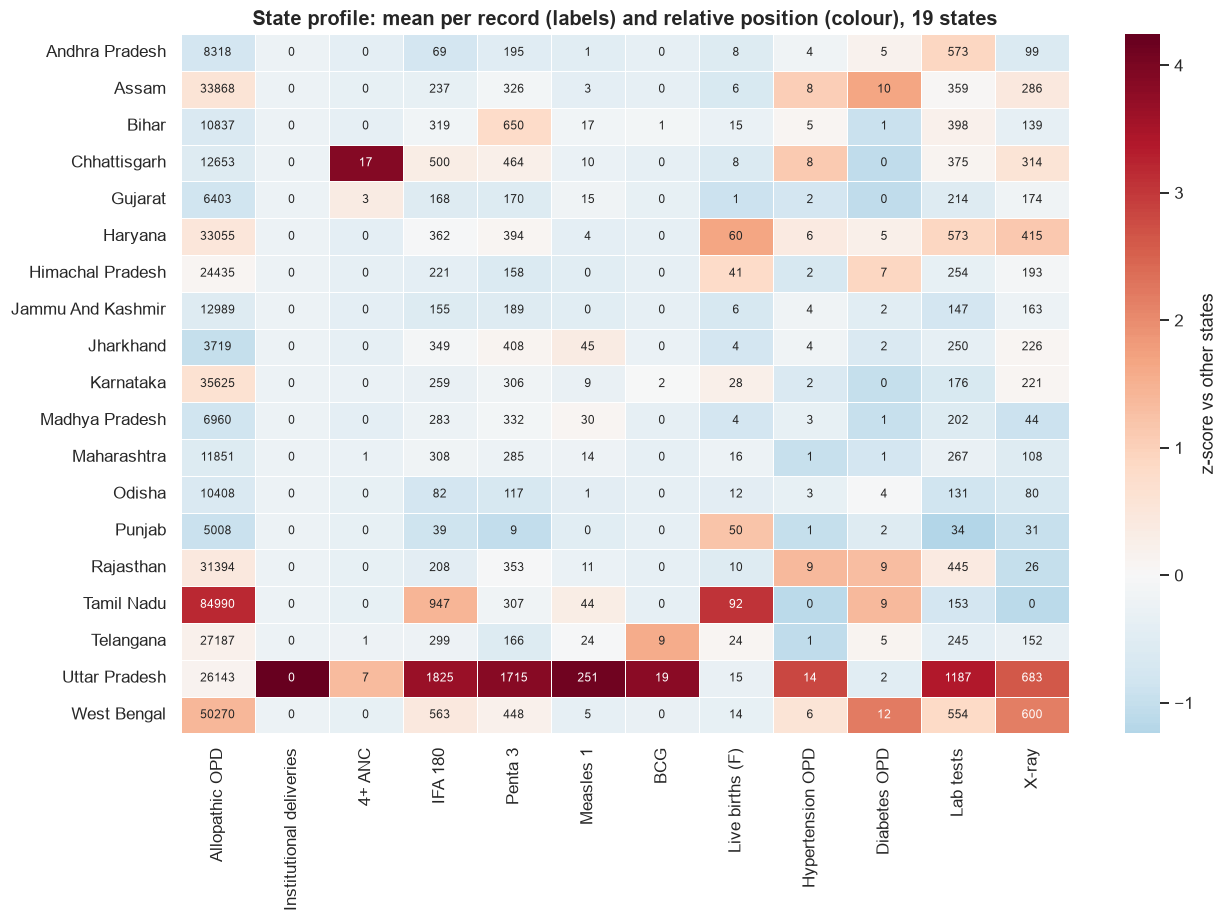

In [21]:
keys = {"allopathic_outpatient_attendance":"Allopathic OPD","inst_deliv_csec":"Institutional deliveries",
        "pw_4plus_anc":"4+ ANC","pw_ifa180":"IFA 180","child_penta3":"Penta 3","child_meas1":"Measles 1",
        "child_bcg":"BCG","live_birth_female":"Live births (F)","outpatient_hypertension":"Hypertension OPD",
        "outpatient_diabetes":"Diabetes OPD","lab_tests_done":"Lab tests","xray_tests":"X-ray"}
n = df.state_name.value_counts()
eligible = n[n >= 8].index
sm = df[df.state_name.isin(eligible)].groupby("state_name")[list(keys)].mean().rename(columns=keys)
z = (sm - sm.mean()) / sm.std(ddof=0).replace(0, np.nan)

fig, ax = plt.subplots(figsize=(12, max(5, 0.45*len(z))))
sns.heatmap(z.fillna(0), cmap="RdBu_r", center=0, annot=sm.round(0).astype(int), fmt="d",
            annot_kws={"size":8}, linewidths=.5, cbar_kws={"label":"z-score vs other states"}, ax=ax)
ax.set_title(f"State profile: mean per record (labels) and relative position (colour), {len(z)} states")
ax.set_ylabel(""); plt.tight_layout(); plt.show()

## 10. Relationships between indicators

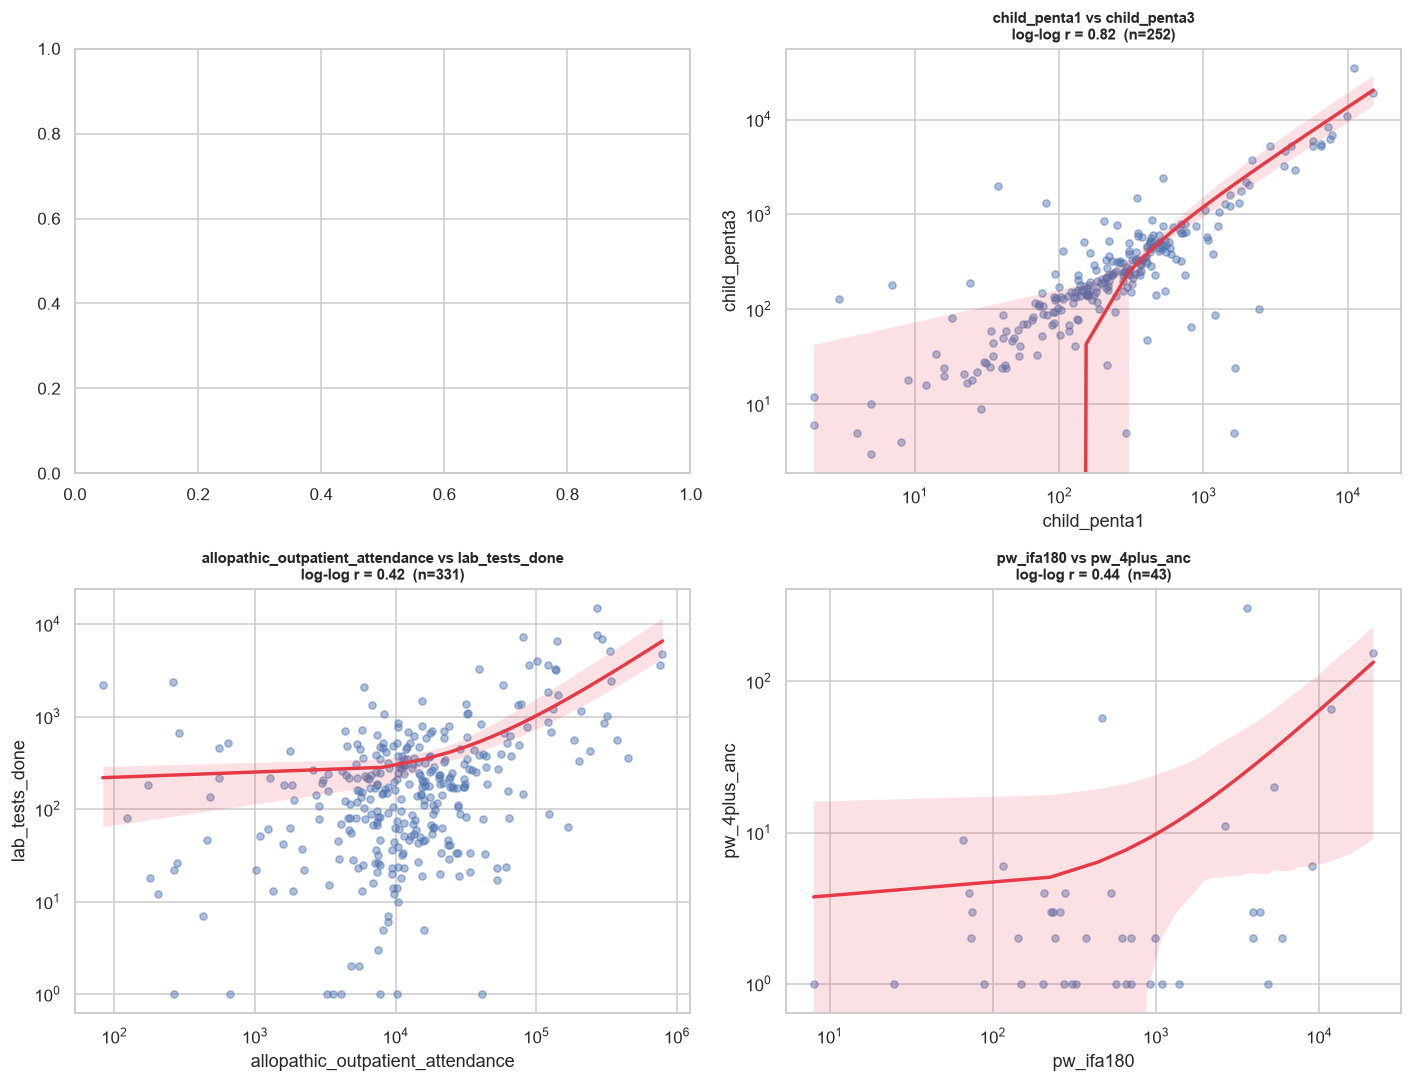

In [22]:
pairs = [("inst_deliv_csec","live_birth_female"),("child_penta1","child_penta3"),
         ("allopathic_outpatient_attendance","lab_tests_done"),("pw_ifa180","pw_4plus_anc")]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (x, y) in zip(axes.ravel(), pairs):
    sub = df[(df[x] > 0) & (df[y] > 0)]
    if len(sub) > 3:
        sns.regplot(data=sub, x=x, y=y, ax=ax, scatter_kws={"alpha":.45,"s":22}, line_kws={"color":"#e63946"})
        ax.set_xscale("log"); ax.set_yscale("log")
        r = np.corrcoef(np.log(sub[x]), np.log(sub[y]))[0,1]
        ax.set_title(f"{x} vs {y}\nlog-log r = {r:.2f}  (n={len(sub)})", fontsize=10)
plt.tight_layout(); plt.show()

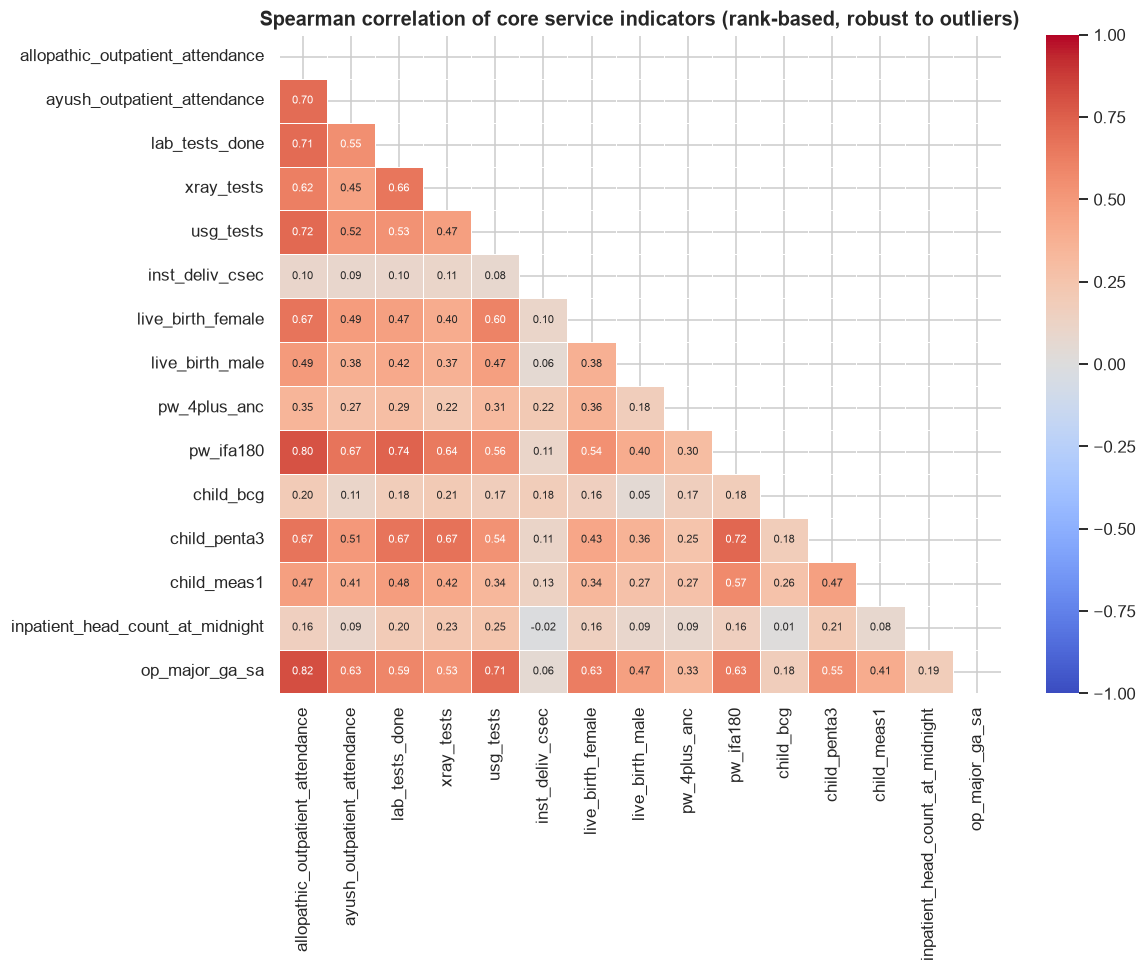

In [23]:
core = ["allopathic_outpatient_attendance","ayush_outpatient_attendance","lab_tests_done","xray_tests","usg_tests",
        "inst_deliv_csec","live_birth_female","live_birth_male","pw_4plus_anc","pw_ifa180",
        "child_bcg","child_penta3","child_meas1","inpatient_head_count_at_midnight","op_major_ga_sa"]
core = [c for c in core if c in df.columns and df[c].nunique() > 1]
corr = df[core].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size":7}, linewidths=.4, ax=ax)
ax.set_title("Spearman correlation of core service indicators (rank-based, robust to outliers)")
plt.tight_layout(); plt.show()

Spearman correlation is used because counts are heavily skewed with many zeros. Strong positive correlations across services mostly reflect **facility size**: a busy sub-district reports more of everything. They are not evidence that one service drives another.

## 11. Findings report and export

In [24]:
def pct(a, b): return a / b if b else np.nan

findings = {}
findings["Records / states / districts"] = f"{len(df)} / {df.state_name.nunique()} / {df.district_name.nunique()}"
findings["Date range"] = f"{df.date.min():%b %Y} to {df.date.max():%b %Y}"
findings["Zero-valued cells"] = f"{zero_share:.1%}"
findings["Records with all indicators zero"] = f"{int(all_zero_rows.sum())} ({all_zero_rows.mean():.1%})"
findings["Allopathic share of OPD"] = f"{pct(df.allopathic_outpatient_attendance.sum(), df.allopathic_outpatient_attendance.sum()+df.ayush_outpatient_attendance.sum()):.1%}"
findings["Institutional share of deliveries"] = f"{pct(d.inst.sum(), d.deliveries.sum()):.1%}"
findings["Median Penta1→3 dropout"] = f"{pr.penta_dropout.median():.1%}"
findings["Low birth weight (of weighed)"] = f"{lbw_rate:.1%}"
findings["Female births per 1000 male"] = f"{sex_ratio:,.0f}"
findings["Maternal deaths recorded"] = f"{int(df[list(mat)].sum().sum())}"
findings["Male share of sterilisation"] = f"{male_share:.1%}"
summary = pd.DataFrame({"Indicator": findings.keys(), "Value": findings.values()})
summary

,Indicator,Value
0,Records / states / districts,500 / 33 / 322
1,Date range,Jan 2019 to May 2021
2,Zero-valued cells,71.0%
3,Records with all indicators zero,135 (27.0%)
4,Allopathic share of OPD,93.5%
5,Institutional share of deliveries,0.0%
6,Median Penta1→3 dropout,7.2%
7,Low birth weight (of weighed),34.3%
8,Female births per 1000 male,"2,342"
9,Maternal deaths recorded,21215


In [25]:
from IPython.display import Markdown, display
display(Markdown(f'''
## Analytical report

### Scope
The sample contains **{len(df)} sub-district records** from **{df.state_name.nunique()} states**, mostly 2019–2020. Of the original 311 columns, 17 were completely empty and were dropped, leaving 294 indicators. The sample is not designed to be nationally representative, so figures describe **this extract**, not India.

### Key findings
1. **Sparse reporting is the main data issue.** {zero_share:.0%} of numeric cells are zero and {int(all_zero_rows.sum())} records report nothing at all. Zero means "none or not reported" here, so any rate computed from these records should exclude zero-denominator rows (as done above).
2. **OPD mix.** Allopathic care accounts for {findings["Allopathic share of OPD"]} of OPD attendance in the sample, with AYUSH share varying widely by state.
3. **Place of delivery.** {findings["Institutional share of deliveries"]} of recorded deliveries were in institutions, with the remainder at home (see the sector and state panels for spread).
4. **Immunisation retention.** The median Penta 1 to Penta 3 dropout is {findings["Median Penta1→3 dropout"]}. A share of records show Penta 3 above Penta 1, which points to catchment or reporting mismatch rather than true negative dropout.
5. **Newborn indicators.** Low birth weight affects {findings["Low birth weight (of weighed)"]} of weighed newborns; recorded female births per 1000 male births is {findings["Female births per 1000 male"]}.
6. **Mortality.** {findings["Maternal deaths recorded"]} maternal deaths were recorded in the sample; the cause breakdown is in Section 5 and is based on small counts.
7. **Family planning.** Male procedures (NSV) make up {findings["Male share of sterilisation"]} of all sterilisation procedures.

### Limitations
- **Sector overlap:** *Total* rows aggregate the other sectors and *Others* (code 9999) is an aggregate sub-district; neither should be summed with the rest.
- **Small and uneven sample:** state comparisons use per-record means and a minimum record count, but remain indicative.
- **No population denominators:** counts cannot be turned into coverage rates without births, eligible population or facility counts.
- **Column label inconsistencies** in the source (for example the Antara dose codes do not line up with their dose labels) mean those fields were not analysed.
- **Zero inflation** inflates "no service" signals; missing reporting cannot be separated from true zero.

### Suggested next steps
- Obtain eligible-population denominators to compute coverage (ANC, immunisation, institutional delivery).
- Use the full dataset to estimate time trends with consistent facility sets.
- Model records with zero reporting separately (reporting completeness analysis).
'''))


## Analytical report

### Scope
The sample contains **500 sub-district records** from **33 states**, mostly 2019–2020. Of the original 311 columns, 17 were completely empty and were dropped, leaving 294 indicators. The sample is not designed to be nationally representative, so figures describe **this extract**, not India.

### Key findings
1. **Sparse reporting is the main data issue.** 71% of numeric cells are zero and 135 records report nothing at all. Zero means "none or not reported" here, so any rate computed from these records should exclude zero-denominator rows (as done above).
2. **OPD mix.** Allopathic care accounts for 93.5% of OPD attendance in the sample, with AYUSH share varying widely by state.
3. **Place of delivery.** 0.0% of recorded deliveries were in institutions, with the remainder at home (see the sector and state panels for spread).
4. **Immunisation retention.** The median Penta 1 to Penta 3 dropout is 7.2%. A share of records show Penta 3 above Penta 1, which points to catchment or reporting mismatch rather than true negative dropout.
5. **Newborn indicators.** Low birth weight affects 34.3% of weighed newborns; recorded female births per 1000 male births is 2,342.
6. **Mortality.** 21215 maternal deaths were recorded in the sample; the cause breakdown is in Section 5 and is based on small counts.
7. **Family planning.** Male procedures (NSV) make up 1.3% of all sterilisation procedures.

### Limitations
- **Sector overlap:** *Total* rows aggregate the other sectors and *Others* (code 9999) is an aggregate sub-district; neither should be summed with the rest.
- **Small and uneven sample:** state comparisons use per-record means and a minimum record count, but remain indicative.
- **No population denominators:** counts cannot be turned into coverage rates without births, eligible population or facility counts.
- **Column label inconsistencies** in the source (for example the Antara dose codes do not line up with their dose labels) mean those fields were not analysed.
- **Zero inflation** inflates "no service" signals; missing reporting cannot be separated from true zero.

### Suggested next steps
- Obtain eligible-population denominators to compute coverage (ANC, immunisation, institutional delivery).
- Use the full dataset to estimate time trends with consistent facility sets.
- Model records with zero reporting separately (reporting completeness analysis).


In [26]:
# Export artefacts
summary.to_csv("health_indicators_key_findings.csv", index=False)
sm.round(2).to_csv("state_profile_per_record_means.csv")
quality.to_csv("data_quality_summary.csv", index=False)
print("Saved: health_indicators_key_findings.csv, state_profile_per_record_means.csv, data_quality_summary.csv")

Saved: health_indicators_key_findings.csv, state_profile_per_record_means.csv, data_quality_summary.csv
